### Importacion de librerias

In [2]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.options.display.max_rows = 10
pd.options.display.max_columns = None

## carga e inspeccion inicial

In [3]:
datos = pd.read_csv('incidentes_limpio.csv')
datos.shape

(395, 48)

In [4]:
datos.head()

,incident_id,date,year,attack_type_code,attack_type_name,incident_kind,severity,confidence_level,real_harm_confirmed,ai_involvement,region,is_landmark_event,source_count,n_attack_types,atk_CRED,atk_EVAL,atk_EXFIL,atk_GOV,atk_INFRA,atk_IPI,atk_MCP,atk_OTHER,atk_ROGUE,atk_SANDBOX,atk_SUPPLY,atk_WEAPON,n_regions,reg_APAC,reg_AU,reg_CN,reg_EU,reg_GLOBAL,reg_HK,reg_JP,reg_KR,reg_LATAM,reg_SEA,reg_TW,reg_UK,reg_US,severity_ord,confidence_ord,ai_confirmed,month_num,quarter,dayofweek,days_since_start,year_month
0,2024-12-01-storm-azure-llmjacking,2024-12-01,2024,CRED,Credential & Secret Theft,incident,high,a,1,confirmed,GLOBAL,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,3,4,1,12,4,6,0,2024-12
1,2025-01-01-maine-town-deepfake-phishing,2025-01-01,2025,OTHER,Unclassified AI Incident,incident,medium,a,1,confirmed,US,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2,4,1,1,1,2,31,2025-01
2,2025-01-20-hk-voice-clone-usdt-fraud,2025-01-20,2025,OTHER,Unclassified AI Incident,incident,medium,a,1,confirmed,HK,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,2,4,1,1,1,0,50,2025-01
3,2025-01-23-operator-fa-bu-bei-jing,2025-01-23,2025,GOV,AI Governance & Policy Failure,policy,info,a,0,confirmed,GLOBAL,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,4,1,1,1,3,53,2025-01
4,2025-01-26-harbin-asian-winter-games-attack,2025-01-26,2025,WEAPON,AI Weaponization & Malicious Tooling,incident,high,d,1,disputed,CN,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,3,1,0,1,1,6,56,2025-01


In [8]:
datos.dtypes

incident_id           str
date                  str
year                int64
attack_type_code      str
attack_type_name      str
                    ...  
month_num           int64
quarter             int64
dayofweek           int64
days_since_start    int64
year_month            str
Length: 48, dtype: object

In [9]:
datos.info

<bound method DataFrame.info of                                            incident_id        date  year  \
0                    2024-12-01-storm-azure-llmjacking  2024-12-01  2024   
1              2025-01-01-maine-town-deepfake-phishing  2025-01-01  2025   
2                 2025-01-20-hk-voice-clone-usdt-fraud  2025-01-20  2025   
3                   2025-01-23-operator-fa-bu-bei-jing  2025-01-23  2025   
4          2025-01-26-harbin-asian-winter-games-attack  2025-01-26  2025   
..                                                 ...         ...   ...   
390    2026-10-07-barracuda-dual-target-email-phishing  2026-10-07  2026   
391           2026-10-07-poellm-canto-incognito-botnet  2026-10-07  2026   
392   2026-10-08-agentcorruption-aws-bedrock-agentcore  2026-10-08  2026   
393           2026-10-08-tensorlake-npm-sdk-compromise  2026-10-08  2026   
394  2026-10-09-anthropic-agent-false-homicide-tip-...  2026-10-09  2026   

    attack_type_code                      attack_type_n

In [10]:
print("Valores faltantes:", datos.isna().sum().sum())
print("Filas duplicadas:", datos.duplicated().sum())
print("incident_id duplicados:", datos['incident_id'].duplicated().sum())

Valores faltantes: 0
Filas duplicadas: 0
incident_id duplicados: 0


In [11]:
datos.nunique()

incident_id         395
date                241
year                  3
attack_type_code     55
attack_type_name     55
                   ... 
month_num            12
quarter               4
dayofweek             7
days_since_start    241
year_month           23
Length: 48, dtype: int64

## preparacion del eda

In [12]:
datos['date'] = pd.to_datetime(datos['date'])

In [13]:
orden_sev = ['info', 'low', 'medium', 'high', 'critical']
datos['severity'] = pd.Categorical(datos['severity'], categories=orden_sev, ordered=True)
datos['confidence_level'] = pd.Categorical(datos['confidence_level'], categories=['a', 'b', 'c', 'd'], ordered=True)

In [14]:
### grupo de columnas
cols_atk = [c for c in datos.columns if c.startswith('atk_')]
cols_reg = [c for c in datos.columns if c.startswith('reg_')]
num_cols = ['n_attack_types', 'n_regions', 'severity_ord', 'confidence_ord', 'days_since_start']
dias = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']

In [15]:
datos.dropna().describe()  # Eliminar valores faltantes

,date,year,real_harm_confirmed,is_landmark_event,source_count,n_attack_types,atk_CRED,atk_EVAL,atk_EXFIL,atk_GOV,atk_INFRA,atk_IPI,atk_MCP,atk_OTHER,atk_ROGUE,atk_SANDBOX,atk_SUPPLY,atk_WEAPON,n_regions,reg_APAC,reg_AU,reg_CN,reg_EU,reg_GLOBAL,reg_HK,reg_JP,reg_KR,reg_LATAM,reg_SEA,reg_TW,reg_UK,reg_US,severity_ord,confidence_ord,ai_confirmed,month_num,quarter,dayofweek,days_since_start
count,395,395.000000,395.000000,395.000000,395.0,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,2026-03-15 05:31:44.810126,2025.688608,0.356962,0.346835,1.0,1.293671,0.162025,0.078481,0.088608,0.169620,0.126582,0.131646,0.078481,0.060759,0.078481,0.065823,0.098734,0.154430,1.035443,0.002532,0.007595,0.050633,0.022785,0.812658,0.005063,0.010127,0.007595,0.010127,0.005063,0.005063,0.005063,0.091139,2.177215,3.837975,0.977215,6.736709,2.531646,2.313924,469.230380
min,2024-12-01 00:00:00,2024.000000,0.000000,0.000000,1.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,2025-11-02 00:00:00,2025.000000,0.000000,0.000000,1.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,4.000000,1.000000,5.000000,2.000000,1.000000,336.000000
50%,2026-05-04 00:00:00,2026.000000,0.000000,0.000000,1.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,4.000000,1.000000,7.000000,3.000000,2.000000,519.000000
75%,2026-08-18 00:00:00,2026.000000,1.000000,1.000000,1.0,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,4.000000,1.000000,9.000000,3.000000,4.000000,625.000000
max,2026-10-09 00:00:00,2026.000000,1.000000,1.000000,1.0,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000,1.000000,12.000000,4.000000,6.000000,677.000000
std,NaN,0.469092,0.479711,0.476566,0.0,0.472423,0.368941,0.269268,0.284537,0.375775,0.332926,0.338534,0.269268,0.239192,0.269268,0.248287,0.298683,0.361819,0.185131,0.050315,0.086927,0.219525,0.149406,0.390680,0.071066,0.100247,0.086927,0.100247,0.071066,0.071066,0.071066,0.288172,1.326798,0.438127,0.149406,2.916180,0.932159,1.697321,178.651193


In [16]:
datos['severity'].value_counts()
datos['real_harm_confirmed'].value_counts()

real_harm_confirmed
0    254
1    141
Name: count, dtype: int64

In [17]:
sev_dano = pd.crosstab(index=datos["severity"], columns=datos["real_harm_confirmed"],
                       rownames=["Valores severity"], colnames=["Valores real_harm_confirmed"],
                       margins=True, margins_name="Total")
sev_dano


Valores real_harm_confirmed,0,1,Total
Valores severity,,,
info,87,0,87
low,5,4,9
medium,82,12,94
high,78,79,157
critical,2,46,48
Total,254,141,395


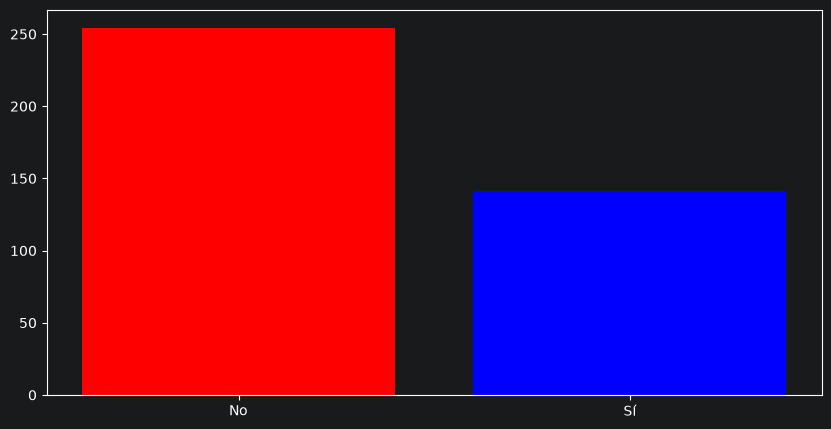

In [18]:
dt_conteo = pd.crosstab(index=datos["real_harm_confirmed"], columns="Conteo", colnames=[""])
alto = [dt_conteo.iloc[0, 0], dt_conteo.iloc[1, 0]]  # Valores en y es frecuencia y Valores en x etiquetas
barras = ('No', 'Sí')

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 5), dpi=100)
ax.bar(barras, alto, color=['red', 'blue'])
plt.show()

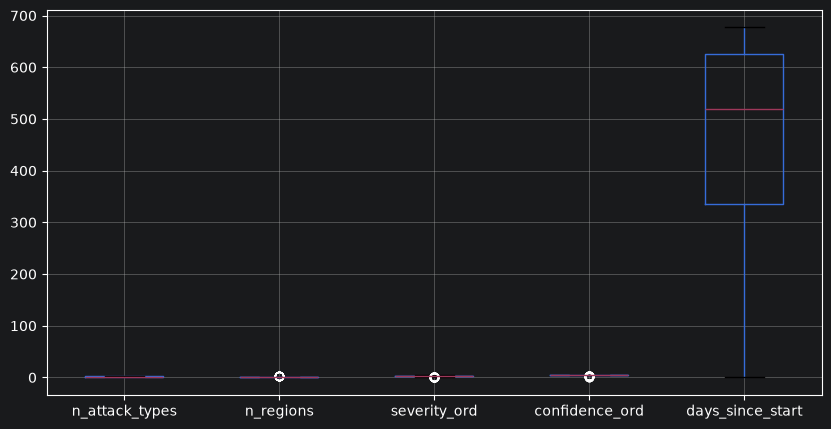

In [19]:
cuanti = ['n_attack_types', 'n_regions', 'severity_ord', 'confidence_ord', 'days_since_start']

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 5), dpi=100)
boxplots = datos[cuanti].boxplot(return_type='axes', ax=ax)
plt.show()

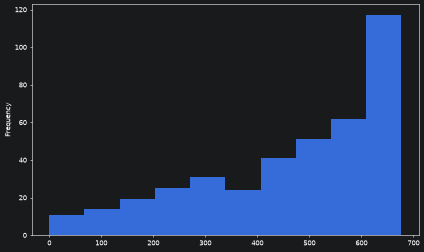

In [20]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 6), dpi=50)
densidad = datos['days_since_start'].plot(kind='hist', ax=ax)
plt.show()

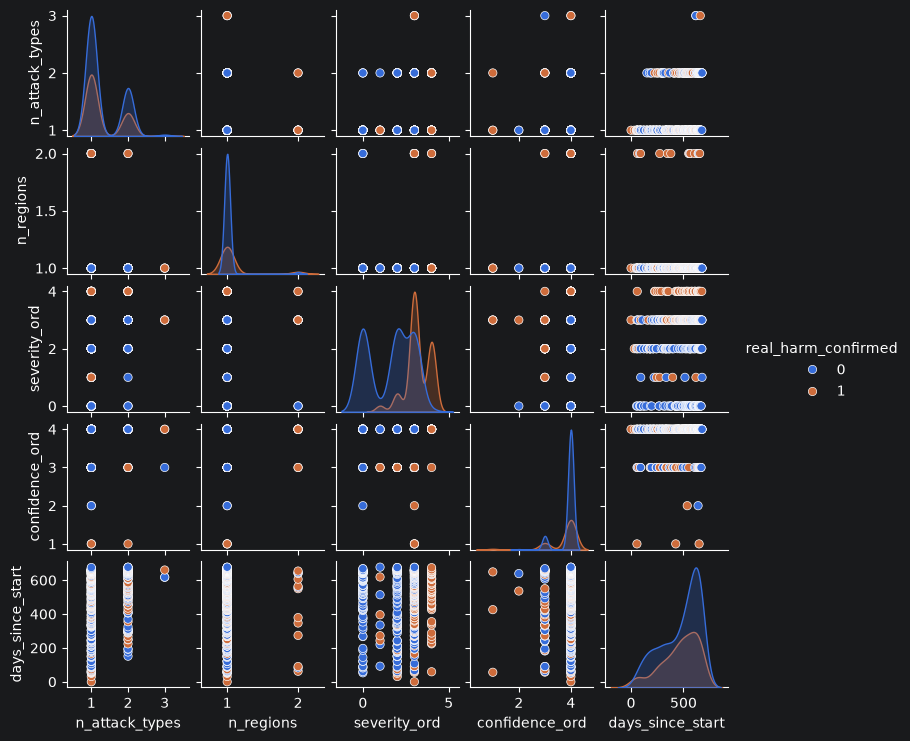

In [21]:
sns.pairplot(datos[cuanti + ['real_harm_confirmed']], hue='real_harm_confirmed', height=1.5)
plt.show()